# Chapter 11 — The Emperor's New AI?

*Companion notebook for Stone (2020), Chapter 11 (a short discussion chapter).*

**Main points of the chapter**

* **AI is possible, even inevitable (Section 11.1).** Birds and brains are physical devices obeying the laws of
  physics; a bird is a flying machine made of organic matter, and a brain is a computational machine made of
  neurons. Just as aeroplanes fly without feathers, machines can be intelligent without neurons.
* **Progress accelerates.** It took ~66 years from the Wright brothers to the Moon landing, and a 1949 prediction
  of half-ton computers could not imagine computers in phones. Progress starts slowly and then seems to
  accelerate (possibly exponentially), making long-range prediction nearly impossible — so the answer to
  "when will AI arrive?" is: *soon*.
* **Yet another revolution? (Section 11.2).** Every revolution is compared to the emperor's new clothes. Critics
  call deep learning "just statistics" or "just faster computers and more data"; cheerleaders over-hype it.
  Both obscure what has actually been discovered.
* **Hinton's parable:** like the tin cans tied to a wedding car, it is the car (the research) that provides the
  motive force, but the cans (the commentators) that make all the noise.

The two cells below make two of these points concrete with the code from earlier chapters: how quickly models grow,
and the fact that a network is only as good as the data it learns from.

In [1]:
import sys, pathlib; sys.path.insert(0, str(pathlib.Path.cwd().parent))
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from scripts.backprop import BackpropNetwork

## How big are the networks in this book?

A fully connected layer from $n_{in}$ to $n_{out}$ units (plus bias) has $(n_{in}+1)\,n_{out}$ weights. The models of
Chapters 2–4 have a handful; even a modest image classifier has hundreds of thousands — and modern networks have
billions. (Sizes below are illustrative architectures of the kind described in the book.)

Ch 2 linear net, 2-1 (no bias)                                     2
Ch 3 perceptron, 2-1 + bias                                        3
Ch 4 XOR backprop net, 2-2-1                                       9
Ch 6 autoencoder, 4-2-4                                           22
MLP for 28x28 digits, 784-500-500-10                         648,010
Ch 7 deep autoencoder, 784-1000-500-250-30 (encoder)       1,418,280


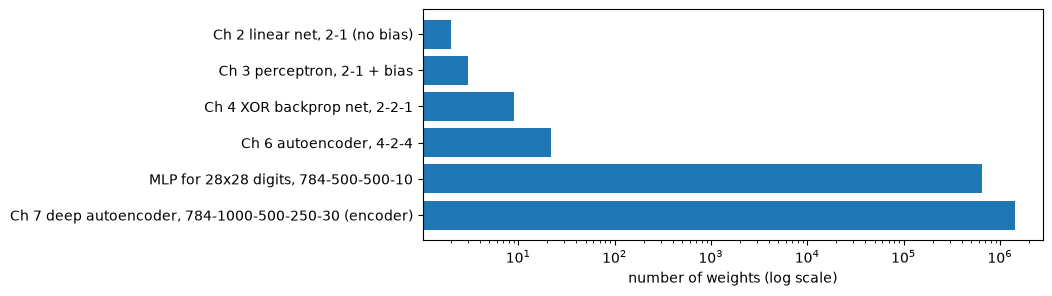

In [2]:
def n_params(layers, bias=True):
    return sum((a + int(bias)) * b for a, b in zip(layers[:-1], layers[1:]))

models = {
    "Ch 2 linear net, 2-1 (no bias)": n_params([2, 1], bias=False),
    "Ch 3 perceptron, 2-1 + bias": n_params([2, 1]),
    "Ch 4 XOR backprop net, 2-2-1": n_params([2, 2, 1]),
    "Ch 6 autoencoder, 4-2-4": n_params([4, 2, 4]),
    "MLP for 28x28 digits, 784-500-500-10": n_params([784, 500, 500, 10]),
    "Ch 7 deep autoencoder, 784-1000-500-250-30 (encoder)": n_params([784, 1000, 500, 250, 30]),
}
for k, v in models.items():
    print(f"{k:55s} {v:>12,d}")
fig, ax = plt.subplots(figsize=(8, 3))
ax.barh(list(models), list(models.values()), color="C0"); ax.set_xscale("log")
ax.set_xlabel("number of weights (log scale)"); ax.invert_yaxis()

## "Just more data"? — generalisation needs data

Critics say deep learning's success is *just* more data. Data certainly matters (Section 4.4): below, the same
1-30-1 backprop network is trained on 6 versus 60 noisy samples of $y=\sin 2x$. With 6 points it fits the
training data perfectly but generalises badly (over-fitting); with 60 points it recovers the underlying function.
But note that the *architecture and learning algorithm* are identical in both cases — data alone is not enough
without a learning machine that can exploit it.

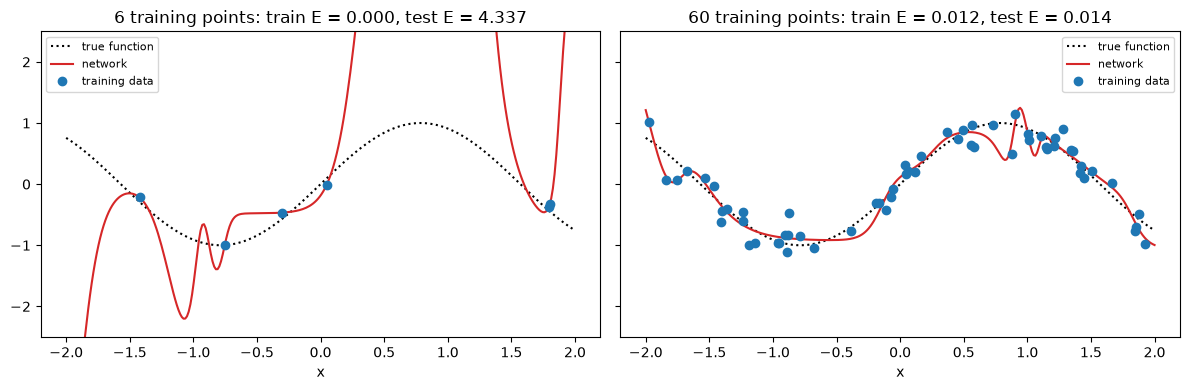

In [3]:
rng = np.random.default_rng(1)
f_true = lambda x: np.sin(2 * x)
xt = np.linspace(-2, 2, 300)[:, None]
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, n in zip(axes, [6, 60]):
    x = rng.uniform(-2, 2, (n, 1))
    y = f_true(x) + rng.normal(0, 0.2, (n, 1))
    net = BackpropNetwork(1, 30, 1, lr=0.5, seed=0, weight_scale=3.0).fit(x, y, n_epochs=20000)
    ax.plot(xt, f_true(xt), "k:", label="true function")
    ax.plot(xt, net.predict(xt), "C3", label="network")
    ax.plot(x, y, "o", color="C0", label="training data")
    ax.set_title(f"{n} training points: train E = {net.history[-1]:.3f}, "
                 f"test E = {net.error(xt, f_true(xt)):.3f}")
    ax.set_ylim(-2.5, 2.5); ax.set_xlabel("x"); ax.legend(fontsize=8)
fig.tight_layout()

## Closing thought

The networks in these notebooks are tiny, but the principles — weighted sums, nonlinear units, gradient descent,
backpropagated errors, and the need for data that constrains the solution — are exactly those that power modern AI.
In Hinton's terms, these are the engine of the car rather than the cans.